# Playground — Generalização (Guilherme)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_generalizacao_guilherme.ipynb)

**Rascunho de desenvolvimento.** Os modelos treinados no GSC (§5 do notebook principal) são testados **sem re-treino**
fora da distribuição: ruído real (DEMAND), outros falantes e salas (AudioMNIST) e outro idioma (MSWC-pt).
Os **resultados finais** não ficam aqui: eles vão para a §10 de `kws_borda_relatorio.ipynb`.

**Nenhuma rede é re-treinada aqui.** Os pesos de cada modelo (seed 0) são carregados do Drive (`runs/`), onde o
notebook principal os salvou. Rode a §5 do principal antes, com os mesmos hiperparâmetros. A única coisa treinada é a
última camada nova do few-shot (§5.3), com o resto da rede congelado.

Roteiro:
1. Carregar os 5 modelos e conferir a acurácia no teste do GSC (tem que bater com a §6 do principal).
2. **DEMAND:** curvas de acurácia × SNR; calibrar o tamanho da amostra; queda por ambiente.
3. **AudioMNIST:** dígitos de outros falantes; nativos × não nativos.
4. **MSWC-pt:** zero-shot mapeado (*sim → yes*) e o **few-shot**: rede congelada e só uma `head` nova treinada com
   K exemplos por palavra, com treino e avaliação de **falantes diferentes**.
5. Levar o few-shot para `dados/mswc_pt.py` (`avaliar_cabeca_linear`) e ligar os flags `RODAR_*` no principal.

In [29]:
#@title Setup — rode esta célula primeiro
#Funciona no Colab (clona o repo e usa o Drive) e localmente/VS Code (usa a pasta do repositório).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/gpeuzinCosta/kws-borda.git"
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    REPO = Path("/content/kws-borda")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=True)     #pega a versão mais nova
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)

    #Drive: cache de MFCC, runs e resultados PERSISTEM entre sessões
    #Disco local (/content/data): áudios extraídos, leitura rápida (o Drive é lento para 100 mil arquivos)
    os.environ["KWS_DRIVE"] = "/content/drive/MyDrive/kws-borda"
    os.environ["KWS_DATA"] = "/content/data"
else:
    #Local: sobe a partir da pasta atual até achar a raiz do repositório
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())

#A raiz do repo no sys.path deixa importar as pastas: configs, dados, modelos, treino, avaliacao
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import torch
from configs import pastas_projeto, escolher_device

PASTAS = pastas_projeto()
DOWNLOADS = Path(os.environ.get("KWS_DRIVE", REPO)) / "downloads"     #.tar.gz/.zip baixados UMA vez
device = escolher_device()
commit = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()

print(f"Colab: {NO_COLAB} | device: {device} | commit do código: {commit}")
print(f"torch {torch.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else '—'}")
for nome, p in PASTAS.items():
    print(f"  {nome:10s} -> {p}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True | device: cuda | commit do código: 8f762ae
torch 2.14.1+cu130 | GPU: Tesla T4
  dados      -> /content/data
  cache      -> /content/drive/MyDrive/kws-borda/cache
  runs       -> /content/drive/MyDrive/kws-borda/runs
  resultados -> /content/drive/MyDrive/kws-borda/runs


## 1. Hiperparâmetros

Os mesmos do notebook principal: `HYPERPARAMETERS` + `HP_MODELOS` (`configs/__init__.py`, igual ao `hp_modelos` da §2)
com a política de treino da §2 (teto de épocas, scheduler e early stop). O `carregar_run` só aceita um treino salvo se
a política for a mesma, então estes três valores têm de ser **iguais aos da §2 do principal**.

In [30]:
from functools import partial
from configs import HYPERPARAMETERS, HP_MODELOS, montar_hp

MODELOS = ["mlp", "cnn1d", "resnet", "dscnn", "atencao"]
SEED = 0                   #a seed cujo treino é carregado do Drive

#Política de treino da §2 do notebook principal (o configs/__init__.py usa 20 épocas + OneCycle, dos playgrounds)
POLITICA_PRINCIPAL = {'epocas': 50, 'scheduler': 'plateau', 'paciencia': 5}

hyperparameters = {**HYPERPARAMETERS, **POLITICA_PRINCIPAL}
config = partial(montar_hp, hyperparameters, HP_MODELOS)

#Tamanho das amostras (calibrar aqui o tempo de cada parte no Colab)
N_RUIDO = 3000             #áudios de teste do GSC misturados ao DEMAND (o principal usa 3.000)
N_RUIDO_AMBIENTE = 1000    #áudios por ambiente na análise por ambiente
POR_FALANTE = 100          #AudioMNIST: gravações por falante (60 falantes; None = todas, 30.000)
K_SHOTS = [1, 3, 5, 10, 20]   #MSWC-pt: exemplos de treino por palavra no few-shot
REPETICOES = 5             #sorteios dos K exemplos (média ± desvio)

print("tarefa:", hyperparameters["tarefa"], "| política:", POLITICA_PRINCIPAL)

tarefa: gsc35 | política: {'epocas': 50, 'scheduler': 'plateau', 'paciencia': 5}


## 2. Dados do GSC e modelos treinados

O GSC é necessário por dois motivos: os áudios de **teste** são a base do teste de ruído, e a normalização `global`
usa a média e o desvio do MFCC do **treino** (vêm do cache no Drive, sem recalcular).

In [31]:
import subprocess, sys

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "gsc",
                "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
RAIZ_GSC = PASTAS["dados"] / "gsc"

In [32]:
import pandas as pd
from modelos import criar_modelo
from dados import ExtratorMFCC, criar_dataloaders
from treino import carregar_run, mesma_politica, prever
from treino.varredura import carregar_dados
from avaliacao import acuracia

modelos = {}     #{nome: dict(model, extrator, media, desvio)}: o formato que avaliar_ruido espera
linhas = []
for nome in MODELOS:
    hp = config(nome)
    loaders, (media, desvio) = criar_dataloaders(hp, carregar_dados(hp, RAIZ_GSC, PASTAS["cache"]))
    run = carregar_run(PASTAS["runs"], hp, SEED)
    if run is None:
        print(f"[pulando] {nome}: nenhum treino salvo no Drive para a seed {SEED} (rode a §5 do principal)")
        continue
    estado, hist, hp_run = run
    if not mesma_politica(hp_run, hp):
        print(f"[aviso] {nome}: o treino salvo usou outra política "
              f"(epocas={hp_run.get('epocas')}, paciencia={hp_run.get('paciencia')}, scheduler={hp_run.get('scheduler')})")
    model = criar_modelo(nome, hp)
    model.load_state_dict(estado)
    model = model.to(device).eval()
    modelos[nome] = dict(model=model, extrator=ExtratorMFCC.de_hparams(hp), media=media, desvio=desvio)

    #Conferência: a acurácia no teste do GSC tem que bater com a §6 do principal (seed 0)
    y_pred, y_true = prever(model, loaders["teste"])
    linhas.append(dict(modelo=nome, entrada=f"{hp['n_mfcc']}x{hp['n_frames']}", run=Path(hist["pasta"]).name,
                       acc_teste_gsc=acuracia(y_pred, y_true)))

resumo_gsc = pd.DataFrame(linhas).set_index("modelo")
resumo_gsc.round(4)

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}
gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


/content/kws-borda/modelos/atencao.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.encoder = torch.nn.TransformerEncoder(


,entrada,run,acc_teste_gsc
modelo,,,
mlp,10x49,mlp_gsc35_10x49_global_s0_20261111-130028,0.7468
cnn1d,10x49,cnn1d_gsc35_10x49_global_s0_20261111-130519,0.9094
resnet,10x49,resnet_gsc35_10x49_global_s0_20261111-131238,0.9378
dscnn,10x49,dscnn_gsc35_10x49_global_s0_20261111-132307,0.9340
atencao,40x101,atencao_gsc35_40x101_global_s0_20261111-133433,0.9361


## 3. Ruído real (DEMAND)

Ruído ambiente (cozinha, sala, escritório, cafeteria, trânsito, metrô, carro, parque) somado aos áudios de teste
em vários SNRs: 20 dB = quase imperceptível, 0 dB = mesma potência da fala, −5 dB = ruído mais forte que a fala.
Nenhum modelo vê ruído no treino. Cada áudio recebe um trecho de um ambiente sorteado, e **o mesmo trecho** vale
para todos os modelos.

In [33]:
from dados.ruido import carregar_demand

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "demand",
                "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
ruidos = carregar_demand(PASTAS["dados"] / "demand")
print({amb: f"{len(r) / 16000 / 60:.1f} min" for amb, r in ruidos.items()})

{'DKITCHEN': '5.0 min', 'DLIVING': '5.0 min', 'NPARK': '5.0 min', 'OOFFICE': '5.0 min', 'PCAFETER': '5.0 min', 'STRAFFIC': '5.0 min', 'TCAR': '5.0 min', 'TMETRO': '5.0 min'}


In [34]:
#Ouvir antes de medir: o mesmo áudio em cada SNR (um ambiente fixo)
import random
from IPython.display import Audio, display
from dados import listar_split, ler_trecho, rotulo
from dados.ruido import misturar_ruido

split = listar_split(RAIZ_GSC, hyperparameters["tarefa"])
exemplo = split["teste"][0]
wav = ler_trecho(RAIZ_GSC, exemplo)
print("palavra:", exemplo.split("/")[0])
for snr in [None] + hyperparameters["snrs_db"]:
    w = wav if snr is None else misturar_ruido(wav, ruidos["PCAFETER"], snr, random.Random(0))
    print("limpo" if snr is None else f"{snr} dB")
    display(Audio(w.numpy(), rate=16000))

palavra: backward
limpo


20 dB


10 dB


5 dB


0 dB


-5 dB


3000 áudios de teste (de 11005, 27%) | 6 condições: ['limpo', 20, 10, 5, 0, -5]
18,000 classificações por modelo | 90,000 no total (5 modelos)
limpo {'mlp': '75.2%', 'cnn1d': '91.2%', 'resnet': '94.0%', 'dscnn': '93.5%', 'atencao': '94.2%'}
20 {'mlp': '72.9%', 'cnn1d': '89.6%', 'resnet': '93.2%', 'dscnn': '92.8%', 'atencao': '93.4%'}
10 {'mlp': '67.8%', 'cnn1d': '85.7%', 'resnet': '89.9%', 'dscnn': '89.8%', 'atencao': '90.4%'}
5 {'mlp': '61.1%', 'cnn1d': '79.8%', 'resnet': '86.7%', 'dscnn': '86.4%', 'atencao': '86.4%'}
0 {'mlp': '53.7%', 'cnn1d': '71.9%', 'resnet': '81.4%', 'dscnn': '79.6%', 'atencao': '78.9%'}
-5 {'mlp': '44.2%', 'cnn1d': '59.5%', 'resnet': '70.0%', 'dscnn': '68.7%', 'atencao': '63.6%'}


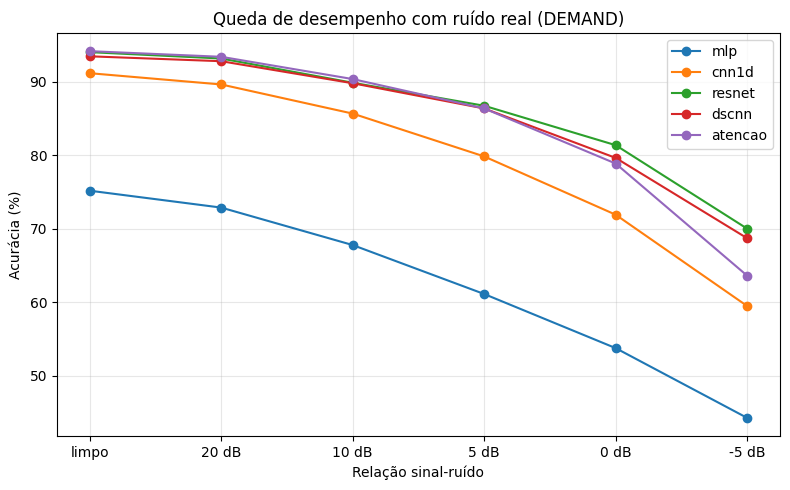

CPU times: user 7.51 s, sys: 551 ms, total: 8.06 s
Wall time: 12.2 s


In [35]:
%%time
import torch
from avaliacao import avaliar_ruido
from avaliacao.graficos import curvas_ruido

amostra = random.Random(0).sample(split["teste"], N_RUIDO)
wavs = [ler_trecho(RAIZ_GSC, rel) for rel in amostra]
y = torch.tensor([rotulo(rel, hyperparameters["tarefa"]) for rel in amostra])

snrs = hyperparameters["snrs_db"]
condicoes = ["limpo"] + snrs
print(f"{len(wavs)} áudios de teste (de {len(split['teste'])}, {len(wavs) / len(split['teste']):.0%}) | "
      f"{len(condicoes)} condições: {condicoes}")
print(f"{len(wavs) * len(condicoes):,} classificações por modelo | "
      f"{len(wavs) * len(condicoes) * len(modelos):,} no total ({len(modelos)} modelos)")
res_ruido = avaliar_ruido(modelos, wavs, y, ruidos, snrs)
curvas_ruido(res_ruido, snrs)

In [36]:
#Queda em pontos percentuais em relação ao áudio limpo (quem é mais robusto, e não só quem começa mais alto)
tabela_ruido = pd.DataFrame(res_ruido).T * 100
queda = tabela_ruido[snrs].sub(tabela_ruido["limpo"], axis=0)
display(tabela_ruido.round(1))
print("queda em p.p. em relação ao limpo:")
display(queda.round(1))

,limpo,20,10,5,0,-5
mlp,75.2,72.9,67.8,61.1,53.7,44.2
cnn1d,91.2,89.6,85.7,79.8,71.9,59.5
resnet,94.0,93.2,89.9,86.7,81.4,70.0
dscnn,93.5,92.8,89.8,86.4,79.6,68.7
atencao,94.2,93.4,90.4,86.4,78.9,63.6


queda em p.p. em relação ao limpo:


,20,10,5,0,-5
mlp,-2.3,-7.4,-14.1,-21.4,-30.9
cnn1d,-1.5,-5.5,-11.3,-19.3,-31.7
resnet,-0.9,-4.2,-7.3,-12.7,-24.0
dscnn,-0.7,-3.7,-7.1,-13.8,-24.8
atencao,-0.8,-3.8,-7.8,-15.3,-30.6


### 3.1 Calibração: o tamanho da amostra muda a conclusão?

Com 3.000 áudios, o erro-padrão de uma acurácia perto de 80% é ~0,7 p.p. Aqui o teste de ruído repete a medida com
**outra** amostra do mesmo tamanho: se as diferenças entre modelos forem maiores que a variação entre amostras,
3.000 bastam para a versão final.

In [37]:
%%time
amostra_b = random.Random(1).sample(split["teste"], N_RUIDO)
wavs_b = [ler_trecho(RAIZ_GSC, rel) for rel in amostra_b]
y_b = torch.tensor([rotulo(rel, hyperparameters["tarefa"]) for rel in amostra_b])
res_ruido_b = avaliar_ruido(modelos, wavs_b, y_b, ruidos, snrs, seed=1)

diferenca = (pd.DataFrame(res_ruido_b).T - pd.DataFrame(res_ruido).T) * 100
print("diferença entre as duas amostras (p.p.):")
display(diferenca.round(1))

limpo {'mlp': '74.6%', 'cnn1d': '90.5%', 'resnet': '93.3%', 'dscnn': '92.5%', 'atencao': '93.3%'}
20 {'mlp': '72.6%', 'cnn1d': '88.0%', 'resnet': '92.3%', 'dscnn': '91.7%', 'atencao': '92.8%'}
10 {'mlp': '67.2%', 'cnn1d': '84.3%', 'resnet': '89.9%', 'dscnn': '89.3%', 'atencao': '89.7%'}
5 {'mlp': '61.5%', 'cnn1d': '79.3%', 'resnet': '86.2%', 'dscnn': '85.0%', 'atencao': '84.6%'}
0 {'mlp': '53.2%', 'cnn1d': '71.2%', 'resnet': '79.1%', 'dscnn': '78.4%', 'atencao': '76.7%'}
-5 {'mlp': '45.2%', 'cnn1d': '59.4%', 'resnet': '68.8%', 'dscnn': '67.5%', 'atencao': '61.9%'}
diferença entre as duas amostras (p.p.):


,limpo,20,10,5,0,-5
mlp,-0.6,-0.3,-0.6,0.4,-0.6,0.9
cnn1d,-0.7,-1.6,-1.3,-0.5,-0.7,-0.0
resnet,-0.7,-0.9,0.1,-0.6,-2.3,-1.2
dscnn,-1.0,-1.1,-0.5,-1.4,-1.3,-1.2
atencao,-0.9,-0.6,-0.7,-1.8,-2.2,-1.7


CPU times: user 7.25 s, sys: 834 ms, total: 8.09 s
Wall time: 11.4 s


### 3.2 Por ambiente

Cada ambiente sozinho, em três níveis de ruído: 5, 0 e −5 dB, a faixa em que as curvas da célula anterior se separam.
Ruídos estacionários (carro, trânsito) e ruídos com fala ao fundo (cafeteria) não devem atrapalhar do mesmo jeito.
Um gráfico por nível, todos na mesma escala (0–100%) para comparar entre eles.

--- DKITCHEN
limpo {'mlp': '75.4%', 'cnn1d': '91.4%', 'resnet': '95.0%', 'dscnn': '93.8%', 'atencao': '94.8%'}
5 {'mlp': '61.0%', 'cnn1d': '75.8%', 'resnet': '87.7%', 'dscnn': '84.9%', 'atencao': '86.4%'}
0 {'mlp': '54.5%', 'cnn1d': '65.4%', 'resnet': '83.9%', 'dscnn': '81.3%', 'atencao': '79.6%'}
-5 {'mlp': '43.8%', 'cnn1d': '51.9%', 'resnet': '77.0%', 'dscnn': '74.5%', 'atencao': '66.8%'}
--- DLIVING
limpo {'mlp': '75.4%', 'cnn1d': '91.4%', 'resnet': '95.0%', 'dscnn': '93.8%', 'atencao': '94.8%'}
5 {'mlp': '62.3%', 'cnn1d': '82.5%', 'resnet': '88.3%', 'dscnn': '86.5%', 'atencao': '86.7%'}
0 {'mlp': '50.9%', 'cnn1d': '70.9%', 'resnet': '80.2%', 'dscnn': '80.1%', 'atencao': '74.7%'}
-5 {'mlp': '37.8%', 'cnn1d': '56.9%', 'resnet': '65.5%', 'dscnn': '64.7%', 'atencao': '55.1%'}
--- NPARK
limpo {'mlp': '75.4%', 'cnn1d': '91.4%', 'resnet': '95.0%', 'dscnn': '93.8%', 'atencao': '94.8%'}
5 {'mlp': '56.6%', 'cnn1d': '77.0%', 'resnet': '85.1%', 'dscnn': '84.4%', 'atencao': '84.0%'}
0 {'mlp': '

,DKITCHEN,DLIVING,NPARK,OOFFICE,PCAFETER,STRAFFIC,TCAR,TMETRO
mlp,61.0,62.3,56.6,74.4,50.4,64.4,72.4,62.4
cnn1d,75.8,82.5,77.0,90.6,66.2,85.1,90.8,82.2
resnet,87.7,88.3,85.1,94.0,77.3,91.0,93.6,88.8
dscnn,84.9,86.5,84.4,92.7,76.7,89.4,93.3,87.7
atencao,86.4,86.7,84.0,93.5,78.2,89.3,94.1,85.3


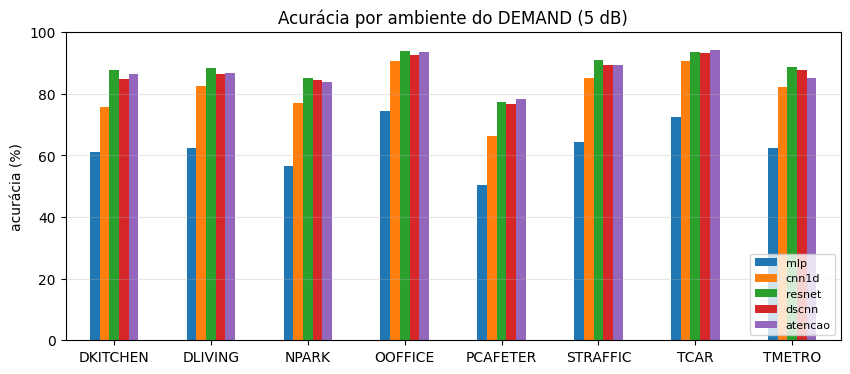


===== 0 dB =====


,DKITCHEN,DLIVING,NPARK,OOFFICE,PCAFETER,STRAFFIC,TCAR,TMETRO
mlp,54.5,50.9,45.2,69.8,35.6,55.9,70.7,52.9
cnn1d,65.4,70.9,65.5,87.7,49.2,78.4,89.9,73.1
resnet,83.9,80.2,76.2,91.7,63.9,86.2,93.2,81.3
dscnn,81.3,80.1,72.6,91.0,59.6,85.1,92.5,80.5
atencao,79.6,74.7,72.8,91.5,54.9,82.3,93.5,73.3


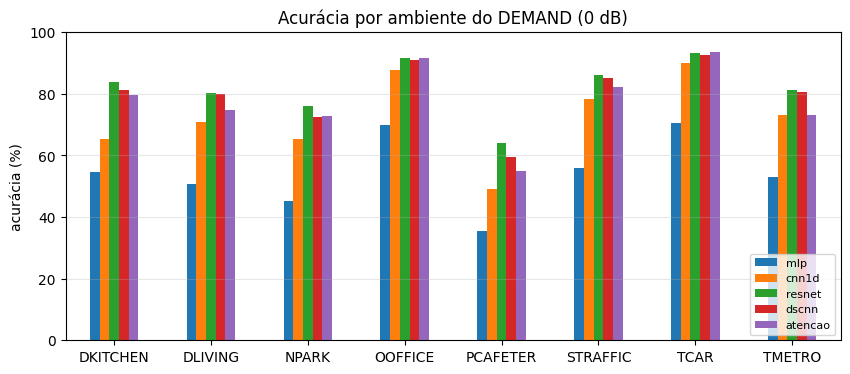


===== -5 dB =====


,DKITCHEN,DLIVING,NPARK,OOFFICE,PCAFETER,STRAFFIC,TCAR,TMETRO
mlp,43.8,37.8,29.9,65.4,21.7,41.0,68.9,42.6
cnn1d,51.9,56.9,50.4,84.6,28.1,66.7,87.8,60.2
resnet,77.0,65.5,62.3,90.2,38.5,77.0,92.7,70.4
dscnn,74.5,64.7,60.5,89.8,35.0,73.5,92.2,66.7
atencao,66.8,55.1,55.2,88.6,26.8,68.1,92.5,58.8


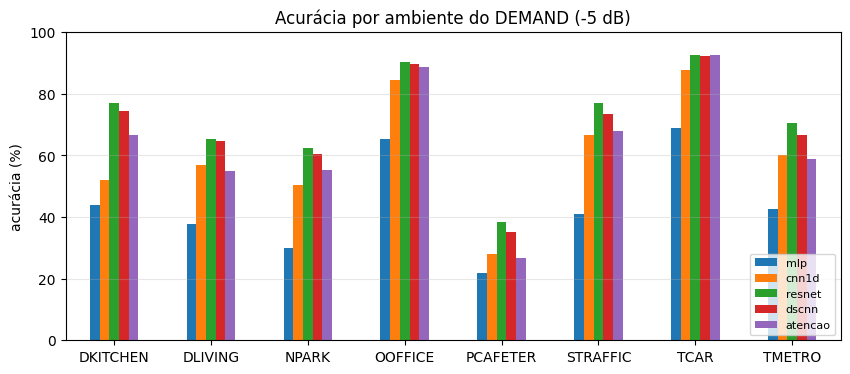

CPU times: user 11 s, sys: 30.9 ms, total: 11 s
Wall time: 11.1 s


In [38]:
%%time
import matplotlib.pyplot as plt

#Reaproveita o avaliar_ruido com um ambiente por vez
#(ele também mede o áudio limpo a cada chamada: não muda o resultado, só gasta um pouco de tempo)
SNRS_AMBIENTE = [5, 0, -5]
wavs_amb, y_amb = wavs[:N_RUIDO_AMBIENTE], y[:N_RUIDO_AMBIENTE]
por_ambiente = {snr: {} for snr in SNRS_AMBIENTE}     #{snr: {ambiente: {modelo: acc}}}
for amb, r in ruidos.items():
    print(f"--- {amb}")
    res = avaliar_ruido(modelos, wavs_amb, y_amb, {amb: r}, SNRS_AMBIENTE)
    for snr in SNRS_AMBIENTE:
        por_ambiente[snr][amb] = {nome: accs[snr] * 100 for nome, accs in res.items()}

print(f"{len(wavs_amb)} áudios × {len(ruidos)} ambientes × {len(SNRS_AMBIENTE)} níveis × {len(modelos)} modelos")
for snr in SNRS_AMBIENTE:
    tabela_amb = pd.DataFrame(por_ambiente[snr])     #linhas: modelos | colunas: ambientes
    print(f"\n===== {snr} dB =====")
    display(tabela_amb.round(1))
    tabela_amb.T.plot.bar(figsize=(10, 4), ylim=(0, 100), ylabel="acurácia (%)",
                          title=f"Acurácia por ambiente do DEMAND ({snr} dB)")
    plt.xticks(rotation=0); plt.legend(loc="lower right", fontsize=8); plt.grid(axis="y", alpha=0.3)
    plt.show()

### 3.3 Matrizes de confusão a −5 dB

O ruído mais forte que a fala. Quais palavras cada modelo ainda reconhece, e para onde vão os erros?
Os mesmos `N_RUIDO` áudios da curva acima, cada um com um trecho de um ambiente sorteado, e **o mesmo áudio com
ruído** para todos os modelos. Matriz normalizada por linha: a diagonal é a acurácia de cada palavra.

3000 áudios de teste a -5 dB

===== mlp | acurácia a -5 dB: 43.9% =====
confusões mais frequentes:


,verdadeira,prevista,fração
0,forward,four,0.36
1,follow,four,0.20
2,no,down,0.19
3,go,down,0.17
4,three,tree,0.16


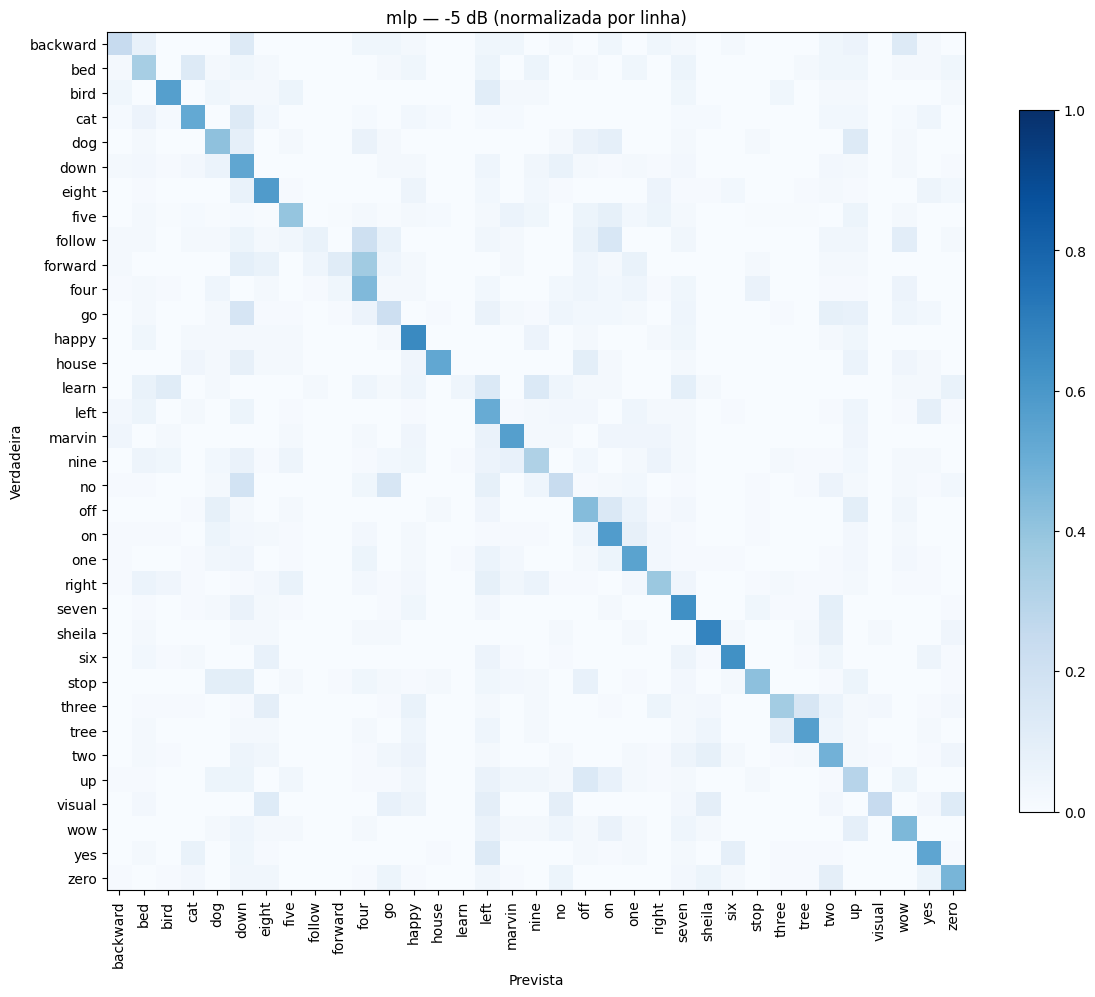


===== cnn1d | acurácia a -5 dB: 59.8% =====
confusões mais frequentes:


,verdadeira,prevista,fração
0,forward,four,0.50
1,up,house,0.20
2,up,off,0.20
3,dog,stop,0.17
4,follow,four,0.17


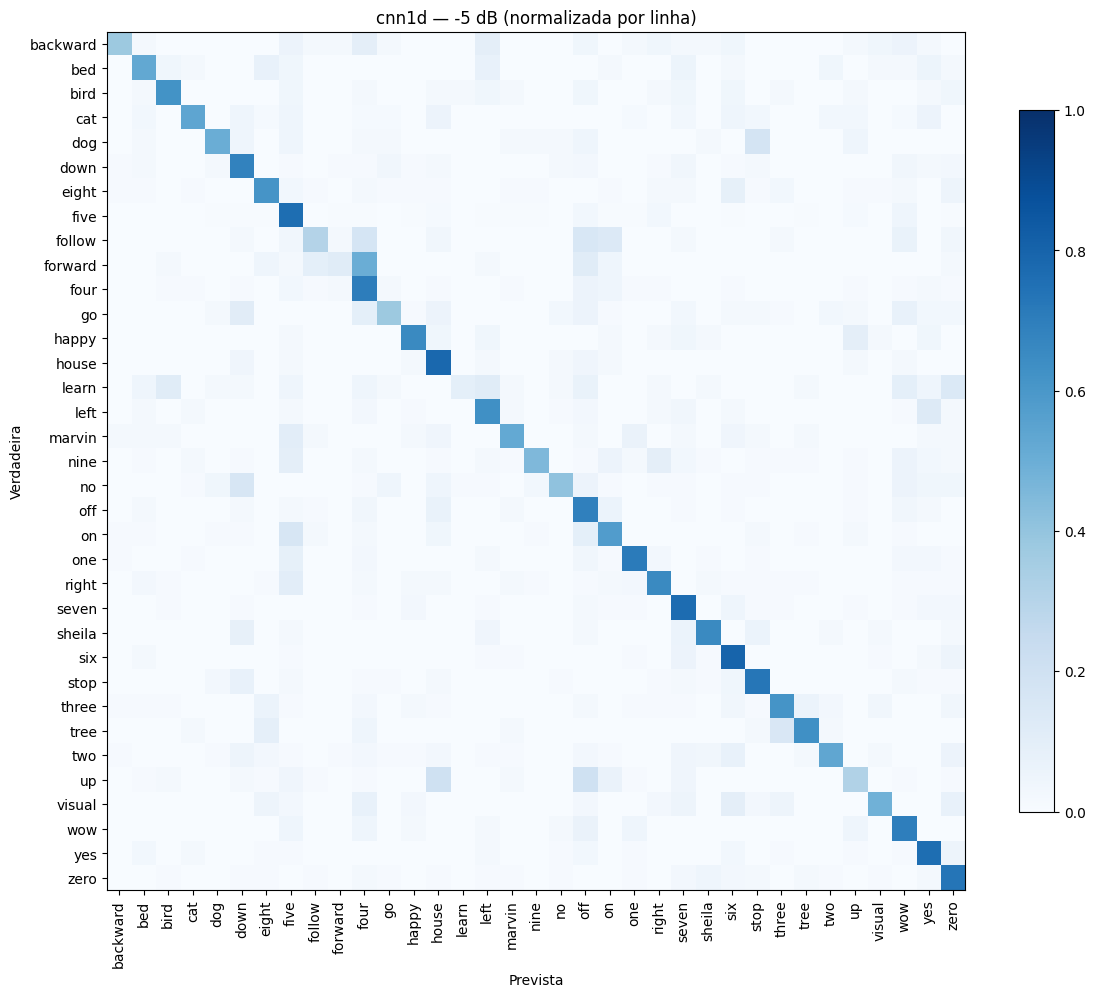


===== resnet | acurácia a -5 dB: 70.4% =====
confusões mais frequentes:


,verdadeira,prevista,fração
0,up,off,0.23
1,forward,four,0.20
2,bed,left,0.16
3,eight,six,0.14
4,two,zero,0.12


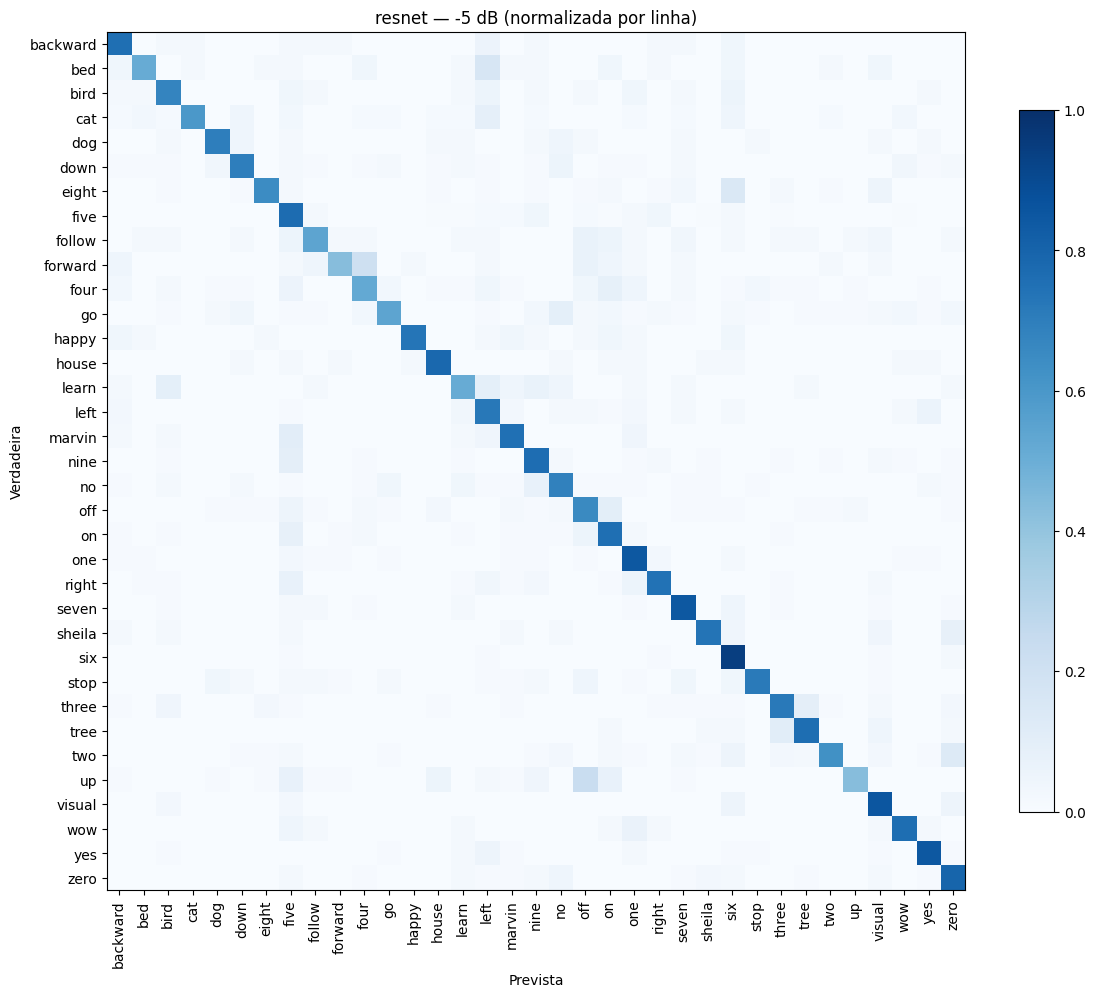


===== dscnn | acurácia a -5 dB: 68.6% =====
confusões mais frequentes:


,verdadeira,prevista,fração
0,tree,three,0.26
1,up,off,0.24
2,forward,four,0.23
3,sheila,zero,0.18
4,follow,on,0.15


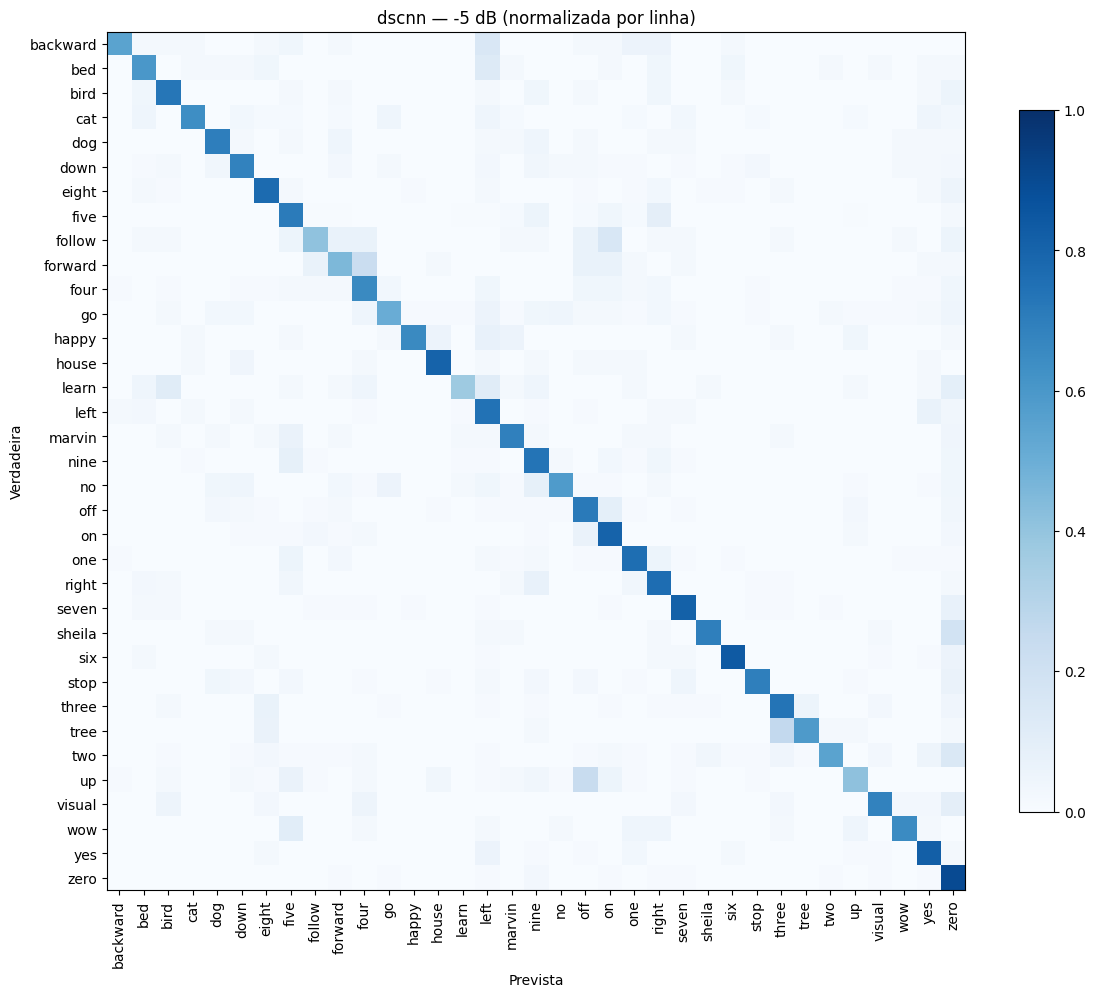


===== atencao | acurácia a -5 dB: 64.9% =====
confusões mais frequentes:


,verdadeira,prevista,fração
0,tree,three,0.28
1,forward,four,0.23
2,eight,six,0.18
3,learn,yes,0.16
4,two,six,0.15


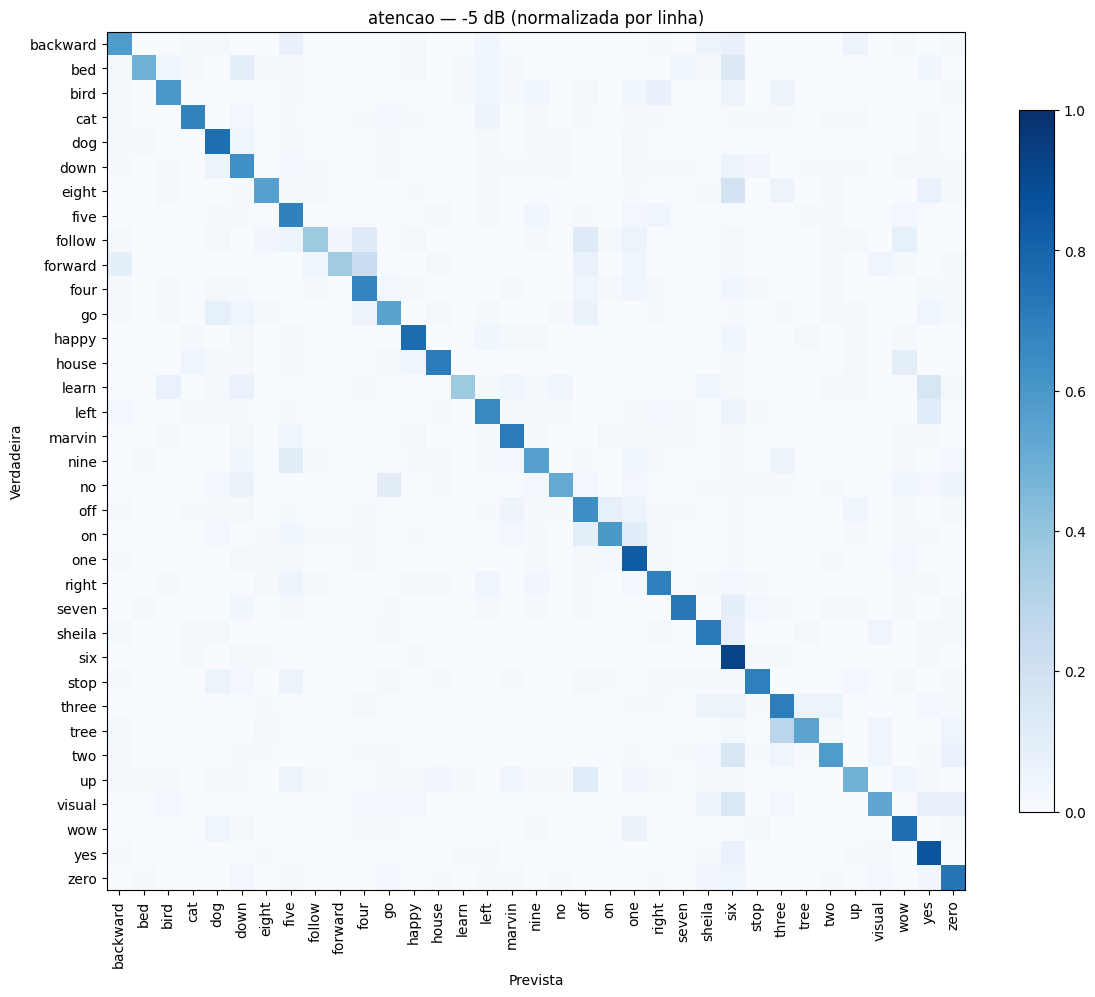

CPU times: user 4.95 s, sys: 31 ms, total: 4.98 s
Wall time: 5.86 s


In [39]:
%%time
from dados import classes_da_tarefa
from dados.ruido import misturar_ruido
from avaliacao import logits_de_wavs, matriz_confusao, top_confusoes
from avaliacao.graficos import plot_matriz_confusao

SNR_MATRIZ = -5
CLASSES = classes_da_tarefa(hyperparameters["tarefa"])

#Mistura UMA vez: todos os modelos recebem exatamente os mesmos áudios com ruído
rng = random.Random(0)
amb_por_audio = [rng.choice(list(ruidos)) for _ in wavs]      #o ambiente de cada áudio (usado na §3.4)
wavs_ruido = [misturar_ruido(w, ruidos[amb], SNR_MATRIZ, rng) for w, amb in zip(wavs, amb_por_audio)]
print(f"{len(wavs_ruido)} áudios de teste a {SNR_MATRIZ} dB")

preds_ruido = {}     #{modelo: previsões a SNR_MATRIZ}, para a §3.4
for nome, m in modelos.items():
    pred = logits_de_wavs(m["model"], wavs_ruido, m["extrator"], m["media"], m["desvio"]).argmax(1)
    preds_ruido[nome] = pred
    cm = matriz_confusao(pred, y, len(CLASSES))
    print(f"\n===== {nome} | acurácia a {SNR_MATRIZ} dB: {(pred == y).float().mean().item() * 100:.1f}% =====")
    print("confusões mais frequentes:")
    display(pd.DataFrame(top_confusoes(cm, CLASSES, k=5), columns=["verdadeira", "prevista", "fração"]).round(2))
    plot_matriz_confusao(cm, CLASSES, titulo=f"{nome} — {SNR_MATRIZ} dB (normalizada por linha)")

### 3.4 Qual ambiente confunde mais?

Os mesmos áudios e previsões da §3.3 (−5 dB), agora separados pelo ambiente que cada áudio recebeu
(~`N_RUIDO` / 8 áudios por ambiente).

1. **Acurácia por ambiente × modelo:** quais ruídos derrubam mais, e se o ranking dos ambientes é o mesmo para todos
   os modelos (se for, o problema está no ruído, não na arquitetura).
2. **Para onde vão os erros:** ruído forte costuma "puxar" as respostas para poucas palavras. Olhando só os erros
   daquele ambiente (os 5 modelos juntos), a tabela mostra as **respostas erradas mais comuns** e que porcentagem dos
   erros cada uma leva. Ex.: "down (30%)" = em 30% dos erros o modelo respondeu "down" quando a palavra era outra.
   Porcentagem alta e concentrada: aquele ruído "soa" como uma palavra específica para o modelo. Baixa e espalhada:
   o ruído só confunde, sem padrão.

áudios por ambiente: {'DKITCHEN': 381, 'DLIVING': 371, 'NPARK': 395, 'OOFFICE': 352, 'PCAFETER': 361, 'STRAFFIC': 369, 'TCAR': 402, 'TMETRO': 369}


,DKITCHEN,DLIVING,NPARK,OOFFICE,PCAFETER,STRAFFIC,TCAR,TMETRO,média
mlp,48.6,37.7,32.9,64.5,24.4,38.5,66.4,37.4,43.8
cnn1d,52.0,52.3,52.9,84.9,29.6,63.4,89.3,52.3,59.6
resnet,77.4,63.6,62.3,88.6,35.5,72.4,92.8,68.8,70.2
dscnn,76.6,61.2,61.8,88.4,32.1,69.4,92.3,65.6,68.4
atencao,70.3,53.1,55.2,88.9,30.7,65.9,93.3,60.4,64.7


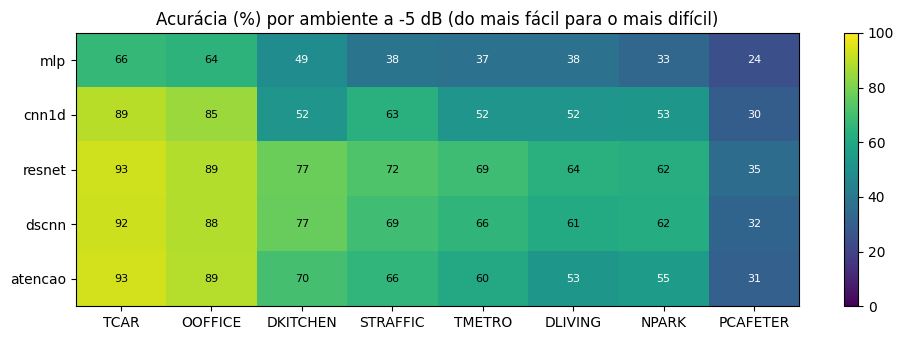

correlação entre os rankings de ambientes dos modelos (1 = mesma ordem):


,mlp,cnn1d,resnet,dscnn,atencao
mlp,1.00,0.67,0.98,0.93,0.93
cnn1d,0.67,1.00,0.69,0.74,0.74
resnet,0.98,0.69,1.00,0.98,0.98
dscnn,0.93,0.74,0.98,1.00,1.00
atencao,0.93,0.74,0.98,1.00,1.00


In [40]:
import numpy as np

amb_t = np.array(amb_por_audio)
AMBIENTES = list(ruidos)
print("áudios por ambiente:", {a: int((amb_t == a).sum()) for a in AMBIENTES})

#1. Acurácia por ambiente x modelo
acc_amb = pd.DataFrame({amb: {nome: (pred[amb_t == amb] == y[amb_t == amb]).float().mean().item() * 100
                              for nome, pred in preds_ruido.items()}
                        for amb in AMBIENTES})
acc_amb["média"] = acc_amb.mean(axis=1)
display(acc_amb.round(1))

#Mapa de calor (modelos x ambientes), ambientes do mais fácil para o mais difícil
ordem = acc_amb[AMBIENTES].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(acc_amb[ordem].values, cmap="viridis", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(ordem))); ax.set_xticklabels(ordem)
ax.set_yticks(range(len(acc_amb))); ax.set_yticklabels(acc_amb.index)
for i in range(len(acc_amb)):
    for j, amb in enumerate(ordem):
        v = acc_amb.loc[acc_amb.index[i], amb]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v < 60 else "black", fontsize=8)
ax.set_title(f"Acurácia (%) por ambiente a {SNR_MATRIZ} dB (do mais fácil para o mais difícil)")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

#O ranking dos ambientes é o mesmo para todos os modelos? (correlação de Spearman entre os rankings)
print("correlação entre os rankings de ambientes dos modelos (1 = mesma ordem):")
display(acc_amb[AMBIENTES].T.corr(method="spearman").round(2))

In [41]:
#2. Para onde vão os erros, por ambiente (todos os modelos juntos)
linhas = []
for amb in AMBIENTES:
    erros_prev, erros_conf = [], []
    for nome, pred in preds_ruido.items():
        sel = torch.from_numpy(amb_t == amb) & (pred != y)
        erros_prev += pred[sel].tolist()
        erros_conf += [(CLASSES[v], CLASSES[p]) for v, p in zip(y[sel].tolist(), pred[sel].tolist())]
    contagem = pd.Series([CLASSES[p] for p in erros_prev]).value_counts()
    pares = pd.Series([f"{v} → {p}" for v, p in erros_conf]).value_counts()
    linhas.append({"ambiente": amb,
                   "nº de erros (5 modelos)": len(erros_prev),
                   "resposta errada mais comum": contagem.index[0],
                   "% dos erros com essa resposta": contagem.iloc[0] / len(erros_prev) * 100,
                   "3 respostas erradas mais comuns (% dos erros)":
                       ", ".join(f"{w} ({n / len(erros_prev) * 100:.0f}%)" for w, n in contagem.head(3).items()),
                   "troca mais comum: certa → respondida (vezes)": f"{pares.index[0]} ({pares.iloc[0]})"})
tabela_erros_amb = (pd.DataFrame(linhas).set_index("ambiente")
                    .sort_values("% dos erros com essa resposta", ascending=False))
display(tabela_erros_amb.round(1))

#Por modelo: a palavra que mais "atrai" os erros em cada ambiente (o modelo colapsa para a mesma palavra?)
atrai = {}
for amb in AMBIENTES:
    atrai[amb] = {}
    for nome, pred in preds_ruido.items():
        erros = pred[torch.from_numpy(amb_t == amb) & (pred != y)]
        if len(erros) == 0:
            atrai[amb][nome] = "sem erros"
            continue
        palavra = erros.mode().values.item()
        atrai[amb][nome] = f"{CLASSES[palavra]} ({(erros == palavra).float().mean().item() * 100:.0f}%)"
atrai = pd.DataFrame(atrai)
print("resposta errada mais comum de cada modelo em cada ambiente (% dos erros do modelo naquele ambiente):")
display(atrai)

,nº de erros (5 modelos),resposta errada mais comum,% dos erros com essa resposta,3 respostas erradas mais comuns (% dos erros),troca mais comum: certa → respondida (vezes)
ambiente,,,,,
TCAR,265,down,14.7,"down (15%), one (9%), on (6%)",go → down (12)
DKITCHEN,667,yes,12.7,"yes (13%), off (12%), six (9%)",left → yes (27)
NPARK,928,left,11.0,"left (11%), five (8%), off (7%)",three → tree (16)
PCAFETER,1255,zero,10.7,"zero (11%), five (7%), six (7%)",two → zero (18)
OOFFICE,298,off,9.4,"off (9%), left (8%), go (7%)",forward → four (9)
TMETRO,795,on,8.1,"on (8%), down (7%), zero (6%)",go → down (15)
STRAFFIC,703,down,7.1,"down (7%), on (6%), off (6%)",off → on (17)
DLIVING,861,off,6.7,"off (7%), on (6%), zero (6%)",two → zero (18)


resposta errada mais comum de cada modelo em cada ambiente (% dos erros do modelo naquele ambiente):


,DKITCHEN,DLIVING,NPARK,OOFFICE,PCAFETER,STRAFFIC,TCAR,TMETRO
mlp,off (10%),down (7%),left (12%),four (8%),down (11%),down (11%),down (15%),down (11%)
cnn1d,yes (22%),wow (12%),house (11%),off (17%),zero (13%),off (10%),down (21%),on (12%)
resnet,off (24%),on (11%),five (19%),left (17%),six (12%),on (11%),down (14%),on (11%)
dscnn,off (22%),zero (13%),left (18%),left (17%),zero (24%),left (8%),bed (10%),zero (13%)
atencao,six (16%),five (8%),six (16%),dog (15%),six (18%),off (9%),one (15%),six (10%)


## 4. AudioMNIST

Dígitos 0–9 de 60 falantes (57 não nativos de inglês), gravados em outras salas. Duas formas de medir:
- **35 classes:** o modelo escolhe entre todas as palavras do GSC (pode confundir "four" com "for"... ou com "forward");
- **só dígitos:** a decisão fica restrita aos 10 logits dos dígitos.

In [42]:
%%time
from dados import CLASSES_GSC, ler_audio
from dados.audiomnist import listar_audiomnist, DIGITOS_EN
from avaliacao import logits_de_wavs

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "audiomnist",
                "--destino", str(PASTAS["dados"])], check=True)
arquivos_am, rotulos_am = listar_audiomnist(PASTAS["dados"] / "audiomnist", por_falante=POR_FALANTE)
wavs_am = [ler_audio(f) for f in arquivos_am]
y_am = torch.tensor(rotulos_am)
idx_digitos = torch.tensor([CLASSES_GSC.index(d) for d in DIGITOS_EN])
falantes_am = [f.parent.name for f in arquivos_am]
print(len(wavs_am), "áudios de", len(set(falantes_am)), "falantes")

logits_am = {nome: logits_de_wavs(m["model"], wavs_am, m["extrator"], m["media"], m["desvio"])
             for nome, m in modelos.items()}
tabela_am = pd.DataFrame([
    dict(modelo=nome,
         acc_35_classes=(L.argmax(1) == idx_digitos[y_am]).float().mean().item() * 100,
         acc_so_digitos=(L[:, idx_digitos].argmax(1) == y_am).float().mean().item() * 100)
    for nome, L in logits_am.items()]).set_index("modelo")
tabela_am.round(1)

6000 áudios de 60 falantes
CPU times: user 17.6 s, sys: 1.87 s, total: 19.4 s
Wall time: 30 s


,acc_35_classes,acc_so_digitos
modelo,,
mlp,91.1,94.8
cnn1d,56.4,57.0
resnet,98.4,99.5
dscnn,97.1,99.1
atencao,97.4,98.8


In [43]:
#Ouvir antes de medir: dígitos sorteados (o que o modelo recebe: 16 kHz, 1 s) e a resposta dos 5 modelos
import json
meta_am = json.load(open(PASTAS["dados"] / "audiomnist" / "data" / "audioMNIST_meta.txt"))

N_OUVIR = 5
sorteados = random.Random(0).sample(range(len(wavs_am)), N_OUVIR)

#Logits só dos áudios sorteados, para cada modelo (com a entrada de cada um)
logits_ouvir = {nome: logits_de_wavs(m["model"], [wavs_am[k] for k in sorteados], m["extrator"], m["media"], m["desvio"])
                for nome, m in modelos.items()}

for j, k in enumerate(sorteados):
    falante = falantes_am[k]
    info = meta_am.get(falante, {})
    certo = DIGITOS_EN[rotulos_am[k]]
    print(f"dígito: {certo} ({rotulos_am[k]}) | falante {falante} | "
          f"sotaque: {info.get('accent', '?')} | nativo: {info.get('native speaker', '?')} | "
          f"sala: {info.get('recordingroom', '?')}")
    display(Audio(wavs_am[k].numpy(), rate=16000))

    #35 classes: a palavra mais provável entre todas | só dígitos: a decisão restrita aos 10 dígitos
    linhas = []
    for nome, L in logits_ouvir.items():
        prob = L[j].softmax(0)
        p35 = CLASSES_GSC[prob.argmax().item()]
        pdig = DIGITOS_EN[prob[idx_digitos].argmax().item()]
        linhas.append({"modelo": nome,
                       "resposta (35 classes)": f"{p35} ({prob.max().item() * 100:.0f}%)",
                       "acertou (35)": "sim" if p35 == certo else "não",
                       "resposta (só dígitos)": pdig,
                       "acertou (dígitos)": "sim" if pdig == certo else "não"})
    display(pd.DataFrame(linhas).set_index("modelo"))

dígito: nine (9) | falante 32 | sotaque: Egyptian_American? | nativo: no | sala: VR-room


,resposta (35 classes),acertou (35),resposta (só dígitos),acertou (dígitos)
modelo,,,,
mlp,nine (90%),sim,nine,sim
cnn1d,nine (97%),sim,nine,sim
resnet,nine (88%),sim,nine,sim
dscnn,nine (100%),sim,nine,sim
atencao,nine (90%),sim,nine,sim


dígito: zero (0) | falante 35 | sotaque: Chinese | nativo: no | sala: vr-room


,resposta (35 classes),acertou (35),resposta (só dígitos),acertou (dígitos)
modelo,,,,
mlp,zero (96%),sim,zero,sim
cnn1d,zero (51%),sim,zero,sim
resnet,zero (93%),sim,zero,sim
dscnn,zero (90%),sim,zero,sim
atencao,zero (92%),sim,zero,sim


dígito: one (1) | falante 04 | sotaque: German | nativo: no | sala: Kino


,resposta (35 classes),acertou (35),resposta (só dígitos),acertou (dígitos)
modelo,,,,
mlp,one (53%),sim,one,sim
cnn1d,five (50%),não,five,não
resnet,one (92%),sim,one,sim
dscnn,one (94%),sim,one,sim
atencao,one (91%),sim,one,sim


dígito: zero (0) | falante 22 | sotaque: German | nativo: no | sala: Ruheraum


,resposta (35 classes),acertou (35),resposta (só dígitos),acertou (dígitos)
modelo,,,,
mlp,zero (76%),sim,zero,sim
cnn1d,zero (32%),sim,zero,sim
resnet,zero (91%),sim,zero,sim
dscnn,zero (70%),sim,zero,sim
atencao,zero (91%),sim,zero,sim


dígito: six (6) | falante 42 | sotaque: Arabic | nativo: no | sala: vr-room


,resposta (35 classes),acertou (35),resposta (só dígitos),acertou (dígitos)
modelo,,,,
mlp,seven (33%),não,seven,não
cnn1d,five (49%),não,five,não
resnet,six (92%),sim,six,sim
dscnn,six (73%),sim,six,sim
atencao,six (90%),sim,six,sim


### 4.1 Nativos × com sotaque

O GSC foi gravado majoritariamente por falantes de inglês americano. O AudioMNIST tem **3 falantes nativos e 57 com
sotaque** (alemão, espanhol, árabe, chinês, indiano...). Como os grupos são muito desiguais, a comparação é feita
**por falante**: primeiro a acurácia de cada falante, depois a média e o desvio de cada grupo. Assim um falante
com muitos áudios não pesa mais que os outros, e dá para ver se a diferença entre os grupos é maior que a variação
dentro de cada um.

**Cuidado na leitura:** 3 nativos é muito pouco. Uma diferença só é convincente se os 3 nativos ficarem acima da
maioria dos falantes com sotaque (gráfico abaixo), não apenas na média.

In [44]:
#Acurácia de cada falante, em cada modelo e nas duas medidas
falantes_t = np.array(falantes_am)
por_falante = []
for nome, L in logits_am.items():
    acerto35 = (L.argmax(1) == idx_digitos[y_am]).float().numpy()
    acerto_dig = (L[:, idx_digitos].argmax(1) == y_am).float().numpy()
    for f in sorted(set(falantes_am)):
        sel = falantes_t == f
        info = meta_am.get(f, {})
        por_falante.append({"modelo": nome, "falante": f,
                            "grupo": "nativo" if info.get("native speaker") == "yes" else "com sotaque",
                            "sotaque": info.get("accent", "?"), "áudios": int(sel.sum()),
                            "acc 35 classes": acerto35[sel].mean() * 100,
                            "acc só dígitos": acerto_dig[sel].mean() * 100})
por_falante = pd.DataFrame(por_falante)
print("falantes por grupo:", por_falante.drop_duplicates("falante")["grupo"].value_counts().to_dict())
print("sotaques dos nativos:", sorted(por_falante.query("grupo == 'nativo'")["sotaque"].unique()))

#Média ± desvio ENTRE falantes, por grupo, e a diferença (nativo − com sotaque) em p.p.
resumo = por_falante.groupby(["modelo", "grupo"])[["acc 35 classes", "acc só dígitos"]].agg(["mean", "std"])
tabela = pd.DataFrame(index=resumo.index.get_level_values(0).unique())
for medida in ["acc 35 classes", "acc só dígitos"]:
    for grupo in ["nativo", "com sotaque"]:
        tabela[f"{medida} | {grupo}"] = [f"{resumo.loc[(m, grupo), (medida, 'mean')]:.1f} ± {resumo.loc[(m, grupo), (medida, 'std')]:.1f}"
                                         for m in tabela.index]
    tabela[f"{medida} | diferença (p.p.)"] = [resumo.loc[(m, "nativo"), (medida, "mean")] - resumo.loc[(m, "com sotaque"), (medida, "mean")]
                                              for m in tabela.index]
display(tabela.round(1))

falantes por grupo: {'com sotaque': 57, 'nativo': 3}
sotaques dos nativos: ['English', 'South African', 'Tamil']


,acc 35 classes | nativo,acc 35 classes | com sotaque,acc 35 classes | diferença (p.p.),acc só dígitos | nativo,acc só dígitos | com sotaque,acc só dígitos | diferença (p.p.)
modelo,,,,,,
atencao,98.0 ± 1.0,97.4 ± 4.7,0.6,99.7 ± 0.6,98.8 ± 3.0,0.9
cnn1d,58.7 ± 20.5,56.2 ± 15.3,2.4,59.0 ± 21.0,56.9 ± 15.2,2.1
dscnn,96.7 ± 1.5,97.1 ± 3.9,-0.5,99.3 ± 0.6,99.1 ± 1.3,0.3
mlp,91.3 ± 8.1,91.1 ± 8.4,0.2,94.0 ± 7.0,94.8 ± 6.5,-0.8
resnet,96.7 ± 2.9,98.5 ± 2.5,-1.8,99.7 ± 0.6,99.5 ± 1.4,0.2


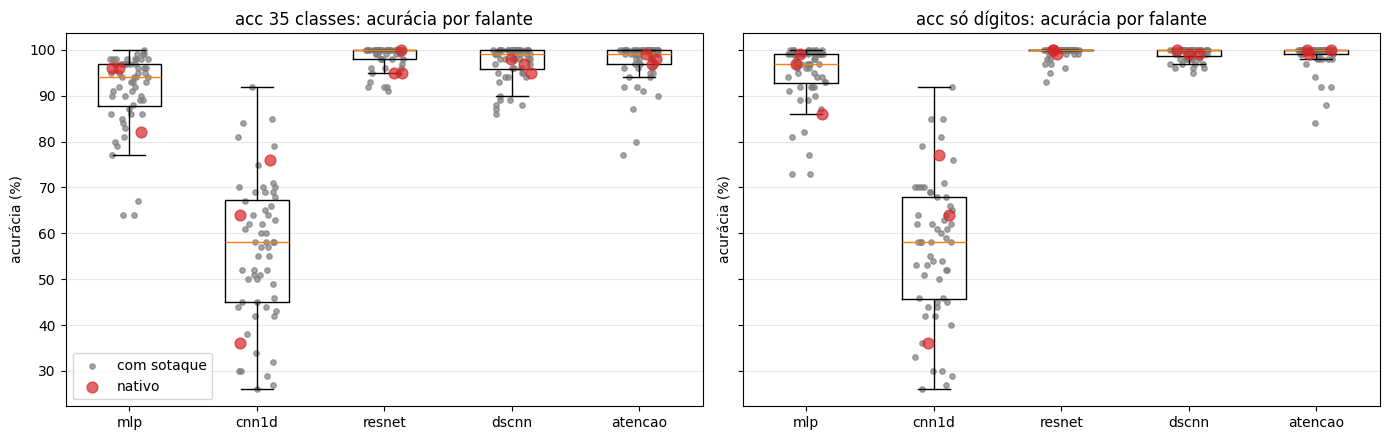

posição dos nativos entre os 60 falantes (só dígitos):


,mlp,cnn1d,resnet,dscnn,atencao
falante 41,14º de 60,6º de 60,40º de 60,22º de 60,40º de 60
falante 60,31º de 60,54º de 60,29º de 60,34º de 60,29º de 60
falante 19,55º de 60,21º de 60,49º de 60,35º de 60,49º de 60


In [45]:
#Cada ponto é um falante: os 3 nativos em destaque. Se eles ficam no meio da nuvem, o sotaque não explica a diferença
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
rng_jit = np.random.default_rng(0)
for ax, medida in zip(axes, ["acc 35 classes", "acc só dígitos"]):
    for i, nome in enumerate(logits_am):
        d = por_falante[por_falante["modelo"] == nome]
        for grupo, cor, tam in [("com sotaque", "tab:gray", 15), ("nativo", "tab:red", 60)]:
            g = d[d["grupo"] == grupo]
            ax.scatter(i + rng_jit.uniform(-0.15, 0.15, len(g)), g[medida], s=tam, color=cor, alpha=0.7,
                       label=grupo if i == 0 else None, zorder=3 if grupo == "nativo" else 2)
        ax.boxplot(d[medida], positions=[i], widths=0.5, showfliers=False)
    ax.set_xticks(range(len(logits_am))); ax.set_xticklabels(list(logits_am))
    ax.set_title(f"{medida}: acurácia por falante"); ax.set_ylabel("acurácia (%)"); ax.grid(axis="y", alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()

#Posição dos nativos no ranking de falantes (1 = melhor falante), em cada modelo, na medida "só dígitos"
ranking = {}
for nome in logits_am:
    d = por_falante[por_falante["modelo"] == nome].sort_values("acc só dígitos", ascending=False).reset_index(drop=True)
    ranking[nome] = {f"falante {f}": f"{i + 1}º de {len(d)}" for i, f in zip(d.index, d["falante"])
                     if d.loc[i, "grupo"] == "nativo"}
print("posição dos nativos entre os 60 falantes (só dígitos):")
display(pd.DataFrame(ranking))

In [46]:
#Por sotaque (média dos falantes de cada sotaque), na medida "só dígitos", do pior para o melhor
por_sotaque = (por_falante.groupby(["sotaque", "modelo"])["acc só dígitos"].mean().unstack())
por_sotaque.insert(0, "falantes", por_falante.drop_duplicates("falante").groupby("sotaque").size())
por_sotaque["média"] = por_sotaque[list(logits_am)].mean(axis=1)
display(por_sotaque.sort_values("média").round(1))

modelo,falantes,atencao,cnn1d,dscnn,mlp,resnet,média
sotaque,,,,,,,
Madras,1,98.000000,50.000000,99.000000,73.000000,100.000000,84.000000
Tamil,1,100.000000,36.000000,99.000000,97.000000,100.000000,86.400002
Arabic,1,92.000000,55.000000,99.000000,89.000000,100.000000,87.000000
French,1,100.000000,44.000000,98.000000,93.000000,100.000000,87.000000
Levant,1,100.000000,44.000000,100.000000,95.000000,100.000000,87.800003
Danish,1,100.000000,53.000000,99.000000,92.000000,100.000000,88.800003
Italian,2,99.500000,58.500000,99.500000,88.000000,99.500000,89.000000
Spanish,2,98.000000,65.500000,96.500000,88.000000,97.500000,89.099998
English,1,99.000000,64.000000,99.000000,86.000000,99.000000,89.400002


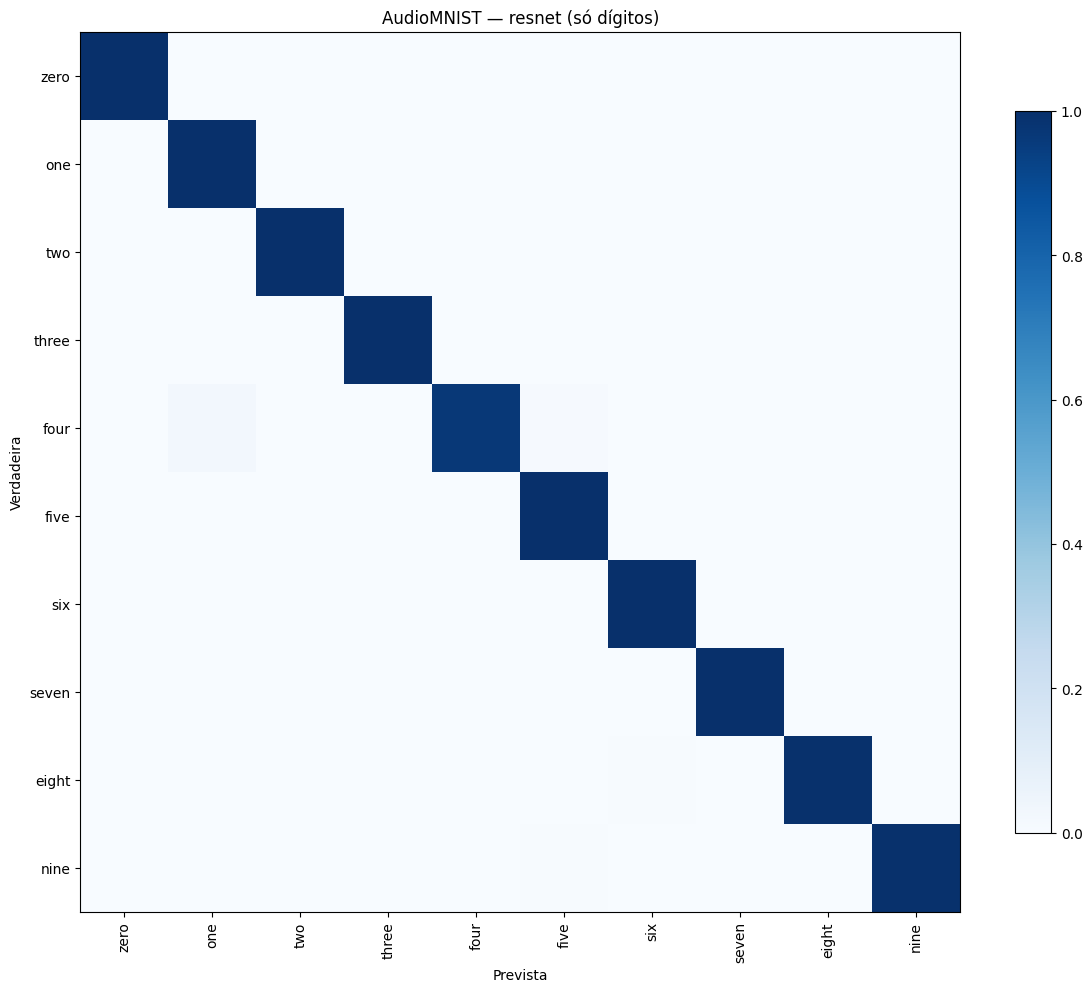

In [47]:
#Onde o melhor modelo erra (só dígitos): matriz de confusão
from avaliacao import matriz_confusao
from avaliacao.graficos import plot_matriz_confusao

melhor = tabela_am["acc_so_digitos"].idxmax()
pred = logits_am[melhor][:, idx_digitos].argmax(1)
plot_matriz_confusao(matriz_confusao(pred, y_am, 10), DIGITOS_EN, titulo=f"AudioMNIST — {melhor} (só dígitos)")

### 4.2 Diagnóstico: por que a CNN 1D cai no AudioMNIST?

A CNN 1D acerta ~91% no GSC e só ~56% no AudioMNIST, enquanto o MLP, que recebe **a mesma entrada** (MFCC 10 × 49),
fica em ~91%. Não é o sotaque (§4.1 não mostrou diferença entre nativos e não nativos).

**Hipótese: o silêncio digital do preenchimento.** As gravações do AudioMNIST têm ~0,6 s; o `fix_length`
(`dados/mfcc.py`) completa até 1 s com **zeros exatos** no final. No GSC os clipes já têm 1 s, com ruído de fundo real
e a palavra mais ou menos no meio. Então ~40% das janelas que a CNN 1D vê são um MFCC de silêncio absoluto, que ela
nunca viu no treino, e o `AdaptiveAvgPool1d` no fim faz a média de todas as janelas, inclusive essas.

**Teste:** os mesmos áudios em 4 versões, nos 5 modelos.
1. **original:** fala no começo, zeros no final (como hoje);
2. **centralizado:** os zeros divididos entre o início e o fim (a palavra no meio, como no GSC);
3. **ruído baixo:** o escritório do DEMAND (OOFFICE) a 30 dB, que preenche o silêncio digital sem atrapalhar a fala;
4. **centralizado + ruído baixo.**

Se a CNN 1D voltar para perto do MLP nas versões 2–4, a causa é o preenchimento, não o modelo nem o sotaque.

AudioMNIST: duração real 0.64 s em média (mín 0.31, máx 1.00) | 36% de cada áudio é zero exato
GSC (teste):  duração real 0.98 s em média | 11% dos clipes têm algum preenchimento


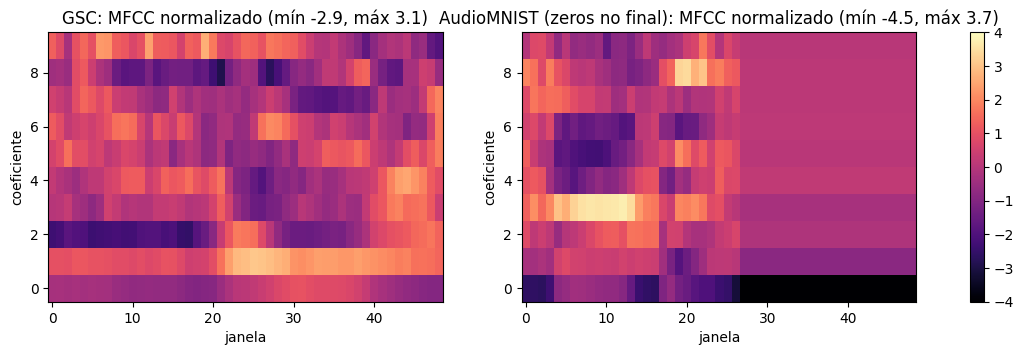

valores fora de [-4, 4] | GSC: 0.19% | AudioMNIST: 3.42%


In [48]:
from dados import normalizar

#1. Quanto de cada áudio é silêncio digital? (zeros exatos no final, vindos do fix_length)
def duracao_real(w):
    """Nº de amostras até o último valor diferente de zero (o resto é o preenchimento do fix_length)."""
    nao_zero = torch.nonzero(w != 0)
    return int(nao_zero[-1]) + 1 if len(nao_zero) else 0

duracoes = torch.tensor([duracao_real(w) for w in wavs_am]).float() / 16000
print(f"AudioMNIST: duração real {duracoes.mean():.2f} s em média (mín {duracoes.min():.2f}, máx {duracoes.max():.2f}) "
      f"| {(1 - duracoes.mean()) * 100:.0f}% de cada áudio é zero exato")
duracoes_gsc = torch.tensor([duracao_real(w) for w in wavs[:500]]).float() / 16000
print(f"GSC (teste):  duração real {duracoes_gsc.mean():.2f} s em média | "
      f"{(duracoes_gsc < 0.999).float().mean() * 100:.0f}% dos clipes têm algum preenchimento")

#2. Como o silêncio digital chega à CNN 1D: o MFCC normalizado de um áudio do AudioMNIST x um do GSC
m = modelos["cnn1d"]
def mfcc_normalizado(w):
    with torch.no_grad():
        x = m["extrator"].cpu()(w)
        return normalizar(x, None if m["media"] is None else m["media"].cpu(),
                          None if m["desvio"] is None else m["desvio"].cpu())[0]

x_am, x_gsc = mfcc_normalizado(wavs_am[0]), mfcc_normalizado(wavs[0])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, x, titulo in [(axes[0], x_gsc, "GSC"), (axes[1], x_am, "AudioMNIST (zeros no final)")]:
    im = ax.imshow(x.numpy(), aspect="auto", origin="lower", cmap="magma", vmin=-4, vmax=4)
    ax.set_title(f"{titulo}: MFCC normalizado (mín {x.min():.1f}, máx {x.max():.1f})")
    ax.set_xlabel("janela"); ax.set_ylabel("coeficiente")
fig.colorbar(im, ax=axes); plt.show()

#Valores extremos: fração de valores do MFCC normalizado fora de [-4, 4] (quase nunca acontece no GSC)
fora = lambda ws: torch.stack([mfcc_normalizado(w) for w in ws]).abs().gt(4).float().mean().item() * 100
print(f"valores fora de [-4, 4] | GSC: {fora(wavs[:300]):.2f}% | AudioMNIST: {fora(wavs_am[:300]):.2f}%")

In [49]:
%%time
from dados.ruido import misturar_ruido

#3. As 4 versões dos mesmos áudios
def centralizar(w):
    """Move metade dos zeros do final para o início: a fala fica no meio do 1 s, como no GSC."""
    return torch.roll(w, (len(w) - duracao_real(w)) // 2)

rng_diag = random.Random(0)
ruido_baixo = lambda w: misturar_ruido(w, ruidos["OOFFICE"], 30, rng_diag)     #escritório a 30 dB

versoes = {"original": wavs_am}
versoes["centralizado"] = [centralizar(w) for w in wavs_am]
versoes["ruído baixo (30 dB)"] = [ruido_baixo(w) for w in wavs_am]
versoes["centralizado + ruído baixo"] = [ruido_baixo(w) for w in versoes["centralizado"]]

linhas = []
for versao, ws in versoes.items():
    for nome, m in modelos.items():
        L = logits_de_wavs(m["model"], ws, m["extrator"], m["media"], m["desvio"])
        linhas.append({"versão": versao, "modelo": nome,
                       "acc 35 classes": (L.argmax(1) == idx_digitos[y_am]).float().mean().item() * 100,
                       "acc só dígitos": (L[:, idx_digitos].argmax(1) == y_am).float().mean().item() * 100})
diag = pd.DataFrame(linhas)

for medida in ["acc 35 classes", "acc só dígitos"]:
    print(f"\n{medida} (%):")
    display(diag.pivot(index="modelo", columns="versão", values=medida)[list(versoes)].round(1))

#Ouvir: o mesmo áudio nas 4 versões
for versao, ws in versoes.items():
    print(versao)
    display(Audio(ws[0].numpy(), rate=16000))


acc 35 classes (%):


versão,original,centralizado,ruído baixo (30 dB),centralizado + ruído baixo
modelo,,,,
atencao,97.4,98.1,97.3,98.1
cnn1d,56.4,55.6,59.2,58.6
dscnn,97.1,98.0,97.0,98.2
mlp,91.1,93.7,90.4,93.6
resnet,98.4,99.3,98.3,99.2



acc só dígitos (%):


versão,original,centralizado,ruído baixo (30 dB),centralizado + ruído baixo
modelo,,,,
atencao,98.8,99.3,98.9,99.3
cnn1d,57.0,56.3,60.2,59.9
dscnn,99.1,99.5,99.1,99.5
mlp,94.8,96.9,94.2,97.0
resnet,99.5,99.7,99.5,99.6


original


centralizado


ruído baixo (30 dB)


centralizado + ruído baixo


CPU times: user 8.23 s, sys: 1.11 s, total: 9.34 s
Wall time: 9.53 s


## 5. MSWC-pt: outro idioma

Palavras em **português** do Multilingual Spoken Words Corpus (clipes de 1 s recortados do Common Voice).

1. **Zero-shot mapeado:** o modelo em inglês acerta o equivalente (*sim → yes*, *cima → up*, *dois → two*)?
   Esperado: perto do acaso, a pronúncia é outra.
2. **Few-shot:** a rede fica **congelada** e só uma `head` nova, com uma saída por palavra em português, é treinada
   com **K exemplos por palavra**. Se o que a rede aprendeu em inglês servir para o português, poucos exemplos bastam.

In [50]:
from dados.mswc_pt import PT2EN, contar_clipes

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "mswc",
                "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
PASTA_CLIPS = PASTAS["dados"] / "mswc" / "pt" / "clips"
contar_clipes(PASTA_CLIPS)

{'sim': 139,
 'não': 3900,
 'esquerda': 18,
 'direita': 25,
 'parar': 26,
 'zero': 89,
 'um': 0,
 'dois': 963,
 'três': 612,
 'quatro': 290,
 'cinco': 255,
 'seis': 145,
 'sete': 140,
 'oito': 117,
 'nove': 110,
 'cima': 98,
 'baixo': 59,
 'ligar': 26,
 'desligar': 4,
 'vai': 441}

### 5.1 Separar treino e teste por falante

O mesmo falante no treino e na avaliação do few-shot inflaria a acurácia (a `head` aprenderia a voz, não a palavra).
O MSWC publica, por idioma, um arquivo de *splits* (`pt_splits.csv`) com o conjunto (TRAIN/DEV/TEST) e o falante
(`SPEAKER`, anonimizado) de cada clipe. **Mas o split oficial não separa falantes:** nas palavras usadas aqui, 195
falantes aparecem no TRAIN e também no DEV/TEST, e dois falantes respondem por ~40% dos clipes.

Por isso a divisão é feita aqui, **por falante**: 70% dos falantes para o treino do few-shot e 30% para a avaliação,
com no máximo `MAX_POR_FALANTE` clipes de cada falante por palavra (para nenhuma voz dominar).

In [51]:
import tarfile
from dados.baixar import baixar

URL_SPLITS_PT = "https://mswc.mlcommons-storage.org/splits/pt.tar.gz"
PASTA_SPLITS = PASTAS["dados"] / "mswc" / "splits"
if not list(PASTA_SPLITS.glob("**/*splits*.csv")):
    tar = baixar(URL_SPLITS_PT, DOWNLOADS / "mswc_pt_splits.tar.gz")
    with tarfile.open(tar) as t:
        t.extractall(PASTA_SPLITS)
csv_splits = next(PASTA_SPLITS.glob("**/*splits*.csv"))
splits_pt = pd.read_csv(csv_splits)
print(csv_splits.name, splits_pt.shape)
splits_pt.head()

pt_splits.csv (199986, 6)


,SET,LINK,WORD,VALID,SPEAKER,GENDER
0,TEST,aba/common_voice_pt_19287080.opus,aba,True,d70dd358a70da404ac99d3142555d78a207e95ddbec3ea...,NAN
1,TRAIN,aba/common_voice_pt_19403672.opus,aba,True,939991dfcf12d8250739f3b4e5ed47e0dc4bf8ffb69810...,MALE
2,DEV,aba/common_voice_pt_19416768.opus,aba,True,30bb34575fe9b8717726a6140ff62bda3f40f45e233f56...,MALE
3,TRAIN,aba/common_voice_pt_19435786.opus,aba,True,9d91497cb25399ad6cf6a4d88548fa84ee3c3687363015...,MALE
4,TRAIN,aba/common_voice_pt_19450571.opus,aba,True,939991dfcf12d8250739f3b4e5ed47e0dc4bf8ffb69810...,MALE


In [52]:
#Só as palavras do PT2EN, só os clipes que existem no disco
splits_pt = splits_pt[splits_pt["WORD"].isin(list(PT2EN))].copy()
splits_pt["caminho"] = [PASTA_CLIPS / link for link in splits_pt["LINK"]]
splits_pt = splits_pt[[c.exists() for c in splits_pt["caminho"]]]

#Divide os FALANTES (não os clipes): ninguém aparece nos dois lados
FRACAO_AVALIACAO = 0.3
MAX_POR_FALANTE = 3         #clipes de cada falante por palavra
falantes = sorted(splits_pt["SPEAKER"].unique())
random.Random(0).shuffle(falantes)
falantes_avaliacao = set(falantes[:int(FRACAO_AVALIACAO * len(falantes))])
splits_pt["conjunto"] = ["avaliacao" if s in falantes_avaliacao else "treino" for s in splits_pt["SPEAKER"]]
splits_pt = splits_pt.sample(frac=1, random_state=0).groupby(["WORD", "SPEAKER"]).head(MAX_POR_FALANTE)

contagem = splits_pt.groupby(["WORD", "conjunto"]).size().unstack(fill_value=0)
display(contagem)

#Palavras usadas: as que têm exemplos de treino para o maior K e uma avaliação minimamente estável
MIN_AVALIACAO = 10
palavras = sorted(w for w, linha in contagem.iterrows()
                  if linha.get("treino", 0) >= max(K_SHOTS) and linha.get("avaliacao", 0) >= MIN_AVALIACAO)
print("palavras usadas:", palavras, f"| acaso = {100 / len(palavras):.1f}%")

conjunto,avaliacao,treino
WORD,,
baixo,10,22
cima,6,44
cinco,37,125
desligar,1,3
direita,4,12
dois,109,276
esquerda,3,9
ligar,6,15
nove,18,74


palavras usadas: ['baixo', 'cinco', 'dois', 'nove', 'não', 'oito', 'quatro', 'seis', 'sete', 'sim', 'três', 'vai', 'zero'] | acaso = 7.7%


In [53]:
#Clipes de cada conjunto (limitados para caber na memória e no tempo)
MAX_TREINO, MAX_AVALIACAO = 100, 100
amostras = []
for w in palavras:
    for conjunto, maximo in [("treino", MAX_TREINO), ("avaliacao", MAX_AVALIACAO)]:
        linhas_w = splits_pt[(splits_pt["WORD"] == w) & (splits_pt["conjunto"] == conjunto)]
        amostras.append(linhas_w.sample(min(maximo, len(linhas_w)), random_state=0))
amostras = pd.concat(amostras).reset_index(drop=True)

wavs_pt = [ler_audio(c) for c in amostras["caminho"]]
y_pt = torch.tensor([palavras.index(w) for w in amostras["WORD"]])
eh_treino = torch.tensor((amostras["conjunto"] == "treino").values)

#Conferência: nenhum falante em comum entre o treino e a avaliação do few-shot (esperado: 0)
falantes_treino = set(amostras.loc[eh_treino.numpy(), "SPEAKER"])
falantes_teste = set(amostras.loc[~eh_treino.numpy(), "SPEAKER"])
print(len(wavs_pt), "clipes | treino:", int(eh_treino.sum()), "| avaliação:", int((~eh_treino).sum()))
print("falantes em comum:", len(falantes_treino & falantes_teste))

1636 clipes | treino: 1087 | avaliação: 549
falantes em comum: 0


In [54]:
#Ouvir alguns clipes (o MSWC é recortado automaticamente: às vezes corta a palavra)
for i in random.Random(0).sample(range(len(wavs_pt)), 3):
    print(amostras.loc[i, "WORD"])
    display(Audio(wavs_pt[i].numpy(), rate=16000))

quatro


zero


quatro


### 5.2 Zero-shot mapeado

Sem treinar nada: entre os logits das palavras em inglês equivalentes, qual o modelo escolhe? Avaliado só nos falantes de avaliação.

In [55]:
idx_en = torch.tensor([CLASSES_GSC.index(PT2EN[w]) for w in palavras])
teste = ~eh_treino
#Acurácia (%) nos falantes de avaliação, escolhendo só entre as palavras em inglês equivalentes
COLUNA_ZERO_SHOT = (f"acurácia zero-shot (%)")

linhas = []
for nome, m in modelos.items():
    L = logits_de_wavs(m["model"], [wavs_pt[i] for i in torch.where(teste)[0]], m["extrator"], m["media"], m["desvio"])
    linhas.append({"modelo": nome,
                   COLUNA_ZERO_SHOT: (L[:, idx_en].argmax(1) == y_pt[teste]).float().mean().item() * 100})
tabela_pt = pd.DataFrame(linhas).set_index("modelo")
tabela_pt.round(1)

,acurácia zero-shot (%)
modelo,
mlp,20.4
cnn1d,22.0
resnet,24.0
dscnn,26.8
atencao,26.2


### 5.3 Few-shot: congelar a rede e treinar só a última camada

1. **Copia** o modelo treinado no GSC (o original não é alterado);
2. **Congela** todos os parâmetros (`requires_grad = False`);
3. **Troca a `head`** (35 saídas em inglês) por uma `Linear` nova, com uma saída por palavra em português.
   Camada criada do zero nasce com `requires_grad = True`: é a única que treina;
4. Treina com o **loop do projeto** (`treinar_uma_epoca` / `validar_uma_epoca`) usando só **K exemplos por palavra**,
   sorteados dos falantes de treino; o otimizador recebe só os parâmetros treináveis;
5. Mede a acurácia nos **falantes de avaliação** (nenhum deles está no treino). Com K pequeno, a escolha dos exemplos
   pesa muito: o sorteio é repetido `REPETICOES` vezes (média ± desvio).

**Cuidado com o BatchNorm:** o `treinar_uma_epoca` chama `model.train()`, que faria o BatchNorm da parte congelada
atualizar as estatísticas acumuladas e ligaria o dropout, mesmo sem gradiente. Por isso o `train()` é sobrescrito
para manter a parte congelada sempre em `eval()`.

**Controle:** a mesma `head` linear treinada direto no **MFCC cru** achatado (sem rede nenhuma). Se a rede não ganhar
do controle, o que ela aprendeu em inglês não está ajudando.

In [56]:
import copy
from torch.utils.data import DataLoader, TensorDataset
from treino import treinar_uma_epoca, validar_uma_epoca


class RedeCongelada(torch.nn.Module):
    """O modelo do GSC congelado, com uma head nova (a única parte treinável)."""

    def __init__(self, modelo_gsc, n_classes):
        super().__init__()
        self.rede = copy.deepcopy(modelo_gsc)          #cópia: o modelo original do GSC não muda

        #Congela todos os parâmetros da rede treinada no GSC
        for p in self.rede.parameters():
            p.requires_grad = False

        #Troca a head (35 palavras em inglês) por uma nova, com uma saída por palavra em português.
        #Camada nova criada do zero: por padrão requires_grad=True, então ela já nasce treinável
        self.rede.head = torch.nn.Linear(self.rede.head.in_features, n_classes)

    def train(self, mode=True):
        super().train(mode)
        self.rede.eval()                #BatchNorm e dropout da parte congelada sempre em modo de avaliação
        self.rede.head.train(mode)      #só a head nova alterna entre treino e avaliação
        return self

    def forward(self, x):
        return self.rede(x)


#Hiperparâmetros do few-shot (poucos exemplos: batch pequeno, várias épocas, lr maior porque a head começa do zero)
HP_FEW = {"epocas": 50, "batch_size": 16, "learning_rate": 1e-2, "weight_decay": 1e-2}

class SoMFCC(torch.nn.Module):
    """Controle: nenhuma rede, só uma head linear sobre o MFCC achatado (n_mfcc x n_frames valores)."""

    def __init__(self, n_entrada, n_classes):
        super().__init__()
        self.head = torch.nn.Linear(n_entrada, n_classes)

    def forward(self, x):
        return self.head(x.flatten(1))


#Teste rápido: parâmetros treináveis x totais (esperado: só os da head nova)
m = next(iter(modelos.values()))["model"]
teste_rede = RedeCongelada(m, len(palavras))
print(f"treináveis: {sum(p.numel() for p in teste_rede.parameters() if p.requires_grad):,} de "
      f"{sum(p.numel() for p in teste_rede.parameters()):,}")

treináveis: 1,677 de 97,549


In [57]:
%%time
from dados import normalizar

def entrada_do_modelo(m, wavs):
    """MFCC normalizado de cada áudio, com a entrada do modelo (o mesmo que logits_de_wavs faz antes da rede)."""
    with torch.no_grad():
        extrator = m["extrator"].cpu()
        x = extrator(torch.stack(wavs))
        return normalizar(x, None if m["media"] is None else m["media"].cpu(),
                          None if m["desvio"] is None else m["desvio"].cpu())


def few_shot_congelado(m, X, y, eh_treino, K, repeticoes=5, seed=0):
    """Rede congelada + head nova treinada com K exemplos por classe. Devolve (média, desvio) da acc em %."""
    rng = random.Random(seed)       #mesma semente para todos os modelos: os mesmos K exemplos sorteados
    idx_treino = {c: torch.where(eh_treino & (y == c))[0].tolist() for c in y.unique().tolist()}
    idx_teste = torch.where(~eh_treino)[0]
    loader_teste = DataLoader(TensorDataset(X[idx_teste], y[idx_teste]), batch_size=256)
    criterion = torch.nn.CrossEntropyLoss()
    accs = []
    for r in range(repeticoes):
        suporte = [i for idxs in idx_treino.values() for i in rng.sample(idxs, K)]
        loader_treino = DataLoader(TensorDataset(X[suporte], y[suporte]), batch_size=HP_FEW["batch_size"], shuffle=True)

        torch.manual_seed(seed + r)     #mesma inicialização da head para a mesma repetição
        rede = RedeCongelada(m["model"], len(palavras)).to(device)
        #Tudo o que não é a head: pesos congelados + buffers (média e variância acumuladas do BatchNorm)
        congelado = lambda: {k: v.detach().clone() for k, v in rede.rede.state_dict().items() if not k.startswith("head.")}
        antes = congelado()

        #O otimizador recebe só os parâmetros treináveis (a head nova)
        optimizer = torch.optim.AdamW([p for p in rede.parameters() if p.requires_grad],
                                      lr=HP_FEW["learning_rate"], weight_decay=HP_FEW["weight_decay"])
        for epoca in range(HP_FEW["epocas"]):
            treinar_uma_epoca(rede, loader_treino, criterion, device, optimizer)
        _, acc = validar_uma_epoca(rede, loader_teste, criterion, device)
        accs.append(acc * 100)

        #Conferência: a parte congelada não mudou (pesos e estatísticas do BatchNorm)
        depois = congelado()
        assert all(torch.equal(antes[k], depois[k]) for k in antes), "a parte congelada mudou!"
    return np.mean(accs), np.std(accs)


#Controle: só a head sobre o MFCC cru, com a entrada da CNN 1D (hello_edge, 10 x 49 = 490 valores)
ent = modelos["cnn1d"] if "cnn1d" in modelos else next(iter(modelos.values()))
X_controle = entrada_do_modelo(ent, wavs_pt)
controle = dict(ent, model=SoMFCC(X_controle[0].numel(), len(palavras)))

linhas = []
for nome, m in list(modelos.items()) + [("controle: MFCC cru", controle)]:
    X_pt = X_controle if nome.startswith("controle") else entrada_do_modelo(m, wavs_pt)
    linha = {"modelo": nome}
    for K in K_SHOTS:
        media_k, desvio_k = few_shot_congelado(m, X_pt, y_pt, eh_treino, K, REPETICOES)
        linha[f"K={K}"] = f"{media_k:.1f} ± {desvio_k:.1f}"
        linha[f"_k{K}"] = media_k
    linhas.append(linha)
    print(nome, {k: v for k, v in linha.items() if k.startswith("K=")})
tabela_congelado = pd.DataFrame(linhas).set_index("modelo")
print(f"\nacurácia (%) nos falantes de avaliação | acaso = {100 / len(palavras):.1f}%")
display(tabela_congelado[[c for c in tabela_congelado if not c.startswith("_")]])

mlp {'K=1': '38.3 ± 2.6', 'K=3': '49.2 ± 3.3', 'K=5': '56.9 ± 2.8', 'K=10': '62.0 ± 1.7', 'K=20': '63.9 ± 2.3'}
cnn1d {'K=1': '41.6 ± 6.3', 'K=3': '65.1 ± 3.2', 'K=5': '70.3 ± 2.5', 'K=10': '76.8 ± 1.6', 'K=20': '81.2 ± 1.9'}
resnet {'K=1': '32.3 ± 3.8', 'K=3': '57.6 ± 4.0', 'K=5': '58.2 ± 0.7', 'K=10': '69.0 ± 1.4', 'K=20': '72.6 ± 1.4'}
dscnn {'K=1': '43.5 ± 4.9', 'K=3': '66.5 ± 3.9', 'K=5': '68.2 ± 4.5', 'K=10': '77.8 ± 2.3', 'K=20': '80.7 ± 2.2'}
atencao {'K=1': '36.3 ± 4.7', 'K=3': '54.2 ± 1.6', 'K=5': '62.7 ± 3.4', 'K=10': '68.1 ± 1.7', 'K=20': '71.9 ± 0.9'}
controle: MFCC cru {'K=1': '28.5 ± 2.7', 'K=3': '48.1 ± 3.2', 'K=5': '55.4 ± 2.5', 'K=10': '65.3 ± 2.1', 'K=20': '71.9 ± 0.9'}

acurácia (%) nos falantes de avaliação | acaso = 7.7%


,K=1,K=3,K=5,K=10,K=20
modelo,,,,,
mlp,38.3 ± 2.6,49.2 ± 3.3,56.9 ± 2.8,62.0 ± 1.7,63.9 ± 2.3
cnn1d,41.6 ± 6.3,65.1 ± 3.2,70.3 ± 2.5,76.8 ± 1.6,81.2 ± 1.9
resnet,32.3 ± 3.8,57.6 ± 4.0,58.2 ± 0.7,69.0 ± 1.4,72.6 ± 1.4
dscnn,43.5 ± 4.9,66.5 ± 3.9,68.2 ± 4.5,77.8 ± 2.3,80.7 ± 2.2
atencao,36.3 ± 4.7,54.2 ± 1.6,62.7 ± 3.4,68.1 ± 1.7,71.9 ± 0.9
controle: MFCC cru,28.5 ± 2.7,48.1 ± 3.2,55.4 ± 2.5,65.3 ± 2.1,71.9 ± 0.9


CPU times: user 2min 28s, sys: 5.58 s, total: 2min 34s
Wall time: 2min 36s


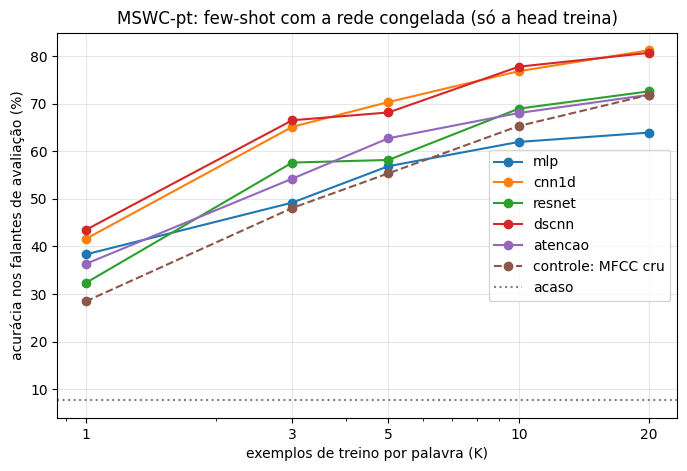

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
for nome, linha in tabela_congelado.iterrows():
    plt.plot(K_SHOTS, [linha[f"_k{K}"] for K in K_SHOTS], marker="o", label=nome,
             linestyle="--" if nome.startswith("controle") else "-")
plt.axhline(100 / len(palavras), color="gray", linestyle=":", label="acaso")
plt.xscale("log"); plt.xticks(K_SHOTS, K_SHOTS)
plt.xlabel("exemplos de treino por palavra (K)"); plt.ylabel("acurácia nos falantes de avaliação (%)")
plt.title("MSWC-pt: few-shot com a rede congelada (só a head treina)"); plt.legend(); plt.grid(alpha=0.3); plt.show()